# 04 · Prevention: how many years of life are within reach?

Notebooks 02 and 03 explained the past and projected the future. This one asks the policy question: **if countries met specific, internationally agreed health targets, how much longer would people live?**

We answer it with **life-table counterfactuals**: take each country's actual death rates by age, lower them in a specific, target-based way, and recompute life expectancy. The difference is the years of life expectancy the target is worth.

| Scenario | What changes | Linked target and interventions |
|---|---|---|
| **Child survival** | Death rates at ages 0-4 are scaled down until under-5 mortality reaches 25 per 1,000 live births | **SDG 3.2.1.** Vaccines, malaria prevention and treatment, skilled birth attendance, care for small and sick newborns, treatment of malnutrition, clean water and sanitation |
| **NCD reduction** | The NCD share of death rates at ages 30-69 is cut by one third | **SDG 3.4.** WHO's "Best Buys": tobacco taxes and cessation support, reducing salt, sugar and unhealthy fats, treating high blood pressure and diabetes in primary care |
| **Combined** | Both of the above | Both sets of programmes |
| **Regional frontier** | Every age-specific death rate is capped at the 25th percentile of the country's WHO region | Shows the gap that is *demonstrably closable*: countries in the same region already achieve these rates |

Sources for the interventions: [UNICEF, child mortality 2024](https://www.unicef.org/press-releases/progress-reducing-child-deaths-slows-49-million-children-under-five-die-2024) · [World Heart Federation on the updated WHO Best Buys (2023)](https://world-heart-federation.org/news/welcoming-the-updated-who-best-buys-at-wha76/)

### Important limits, state these in any write-up
- These are **"what if" calculations, not predictions**. They show what a target is worth, not whether or how it will be reached.
- The NCD share of deaths at 30-69 is estimated from two published probabilities (premature NCD mortality and all-cause mortality at those ages) under a standard competing-risks assumption. It's an approximation.
- Reducing deaths from one cause leaves people exposed to others. Life tables handle this correctly; adding up separate cause-specific estimates would not.
- The base year is the last pre-COVID year, so the results describe structural potential rather than pandemic recovery.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PANEL_PATH, FIGURES_DIR
from src.plotting import set_style, REGION_COLORS, PALETTE, INK, INK_SECONDARY, SURFACE
from src.analysis import load_life_tables, prevention_scenarios, weighted_mean, SDG_U5MR_TARGET

set_style()
pd.set_option("display.width", 140, "display.precision", 2)
panel = pd.read_csv(PANEL_PATH)
lt = load_life_tables()
if lt is None:
    raise FileNotFoundError("No life tables found. Re-run `python -m src.fetch_data` and `python -m src.build_dataset`.")

FOCUS_COUNTRY = "KEN"
FOCUS_REGION = "Africa"
BASE_YEAR = 2019 if 2019 in set(lt["year"]) else int(lt.loc[lt["year"] < 2020, "year"].max())
REGION_ORDER = [r for r in REGION_COLORS if r in set(panel["who_region"])]
SCENARIOS = {"child": "Child survival (SDG 3.2)", "ncd": "NCDs cut by a third (SDG 3.4)",
             "combined": "Both targets", "frontier": "Match regional best performers"}

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png")

prev = prevention_scenarios(lt, panel, BASE_YEAR, "both")
if FOCUS_COUNTRY not in prev.index:
    FOCUS_COUNTRY = prev[prev["who_region"] == FOCUS_REGION].index[0]
    print(f"Focus country not found; using {FOCUS_COUNTRY}")
print(f"Base year {BASE_YEAR}: scenarios computed for {len(prev)} countries")
print(f"Countries already meeting the under-5 target: {(prev['u5mr'] <= SDG_U5MR_TARGET * 1000).sum()} of {len(prev)}")

Base year 2019: scenarios computed for 185 countries
Countries already meeting the under-5 target: 118 of 185


## 1. Years of life within reach, by region

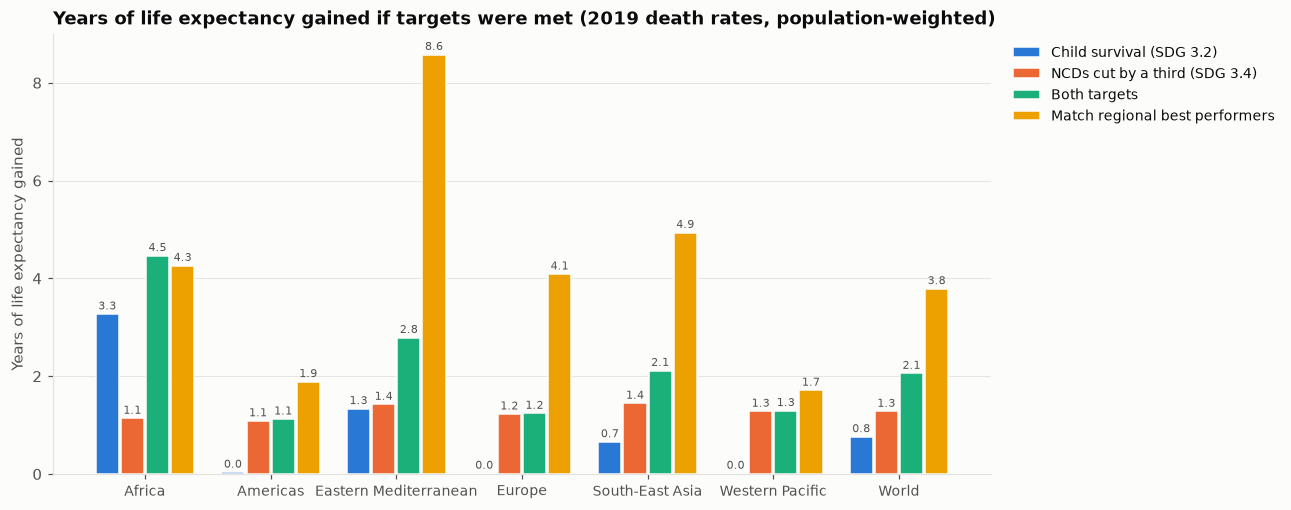

,child,ncd,combined,frontier,e0
who_region,,,,,
Africa,3.27,1.14,4.47,4.26,64.55
Americas,0.04,1.09,1.12,1.89,77.17
Eastern Mediterranean,1.34,1.42,2.79,8.58,70.62
Europe,0.01,1.23,1.24,4.09,78.64
South-East Asia,0.66,1.44,2.12,4.94,71.25
Western Pacific,0.01,1.28,1.29,1.71,77.65
World,0.76,1.28,2.06,3.79,73.68


In [2]:
regional = prev.groupby("who_region").apply(
    lambda g: pd.Series({k: weighted_mean(g, k) for k in SCENARIOS} | {"e0": weighted_mean(g, "e0")}), include_groups=False)
regional.loc["World"] = pd.Series({k: weighted_mean(prev, k) for k in SCENARIOS} | {"e0": weighted_mean(prev, "e0")})
regional = regional.reindex(REGION_ORDER + ["World"])

fig, ax = plt.subplots(figsize=(11, 5.2))
n = len(SCENARIOS)
width = 0.8 / n
x = np.arange(len(regional))
for i, (key, label) in enumerate(SCENARIOS.items()):
    vals = regional[key].to_numpy()
    ax.bar(x + (i - (n - 1) / 2) * width, vals, width=width * 0.92, color=PALETTE[i], label=label,
           edgecolor=SURFACE, linewidth=1)
    for xi, v in zip(x + (i - (n - 1) / 2) * width, vals):
        if np.isfinite(v):
            ax.annotate("met" if key == "child" and v < 0.005 else f"{v:.1f}", xy=(xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5, color=INK_SECONDARY)
ax.set_xticks(x, regional.index, fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Years of life expectancy gained")
ax.set_title(f"Years of life expectancy gained if targets were met ({BASE_YEAR} death rates, population-weighted)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, "20_prevention_regional")
plt.show()

regional.round(2)

"Met" means the region's countries already meet the child-survival target on average, so that scenario adds nothing there.

**How to read this:** compare the bars *within* a region. Where the child-survival bar is tallest, investing in maternal, newborn and child health still offers the biggest return in years of life. Where the NCD bar dominates, the priority has shifted to adults: tobacco, blood pressure, diabetes and diet. Many low- and middle-income countries face **both** at once (the "double burden"), which is exactly why prioritisation is hard and why this kind of analysis is useful.

The **regional frontier** bar is often the largest. It says how much longer people would live if every country achieved death rates that its neighbours already achieve. It's a powerful equity argument, because the gap is clearly closable.

## 2. Country by country in the focus region

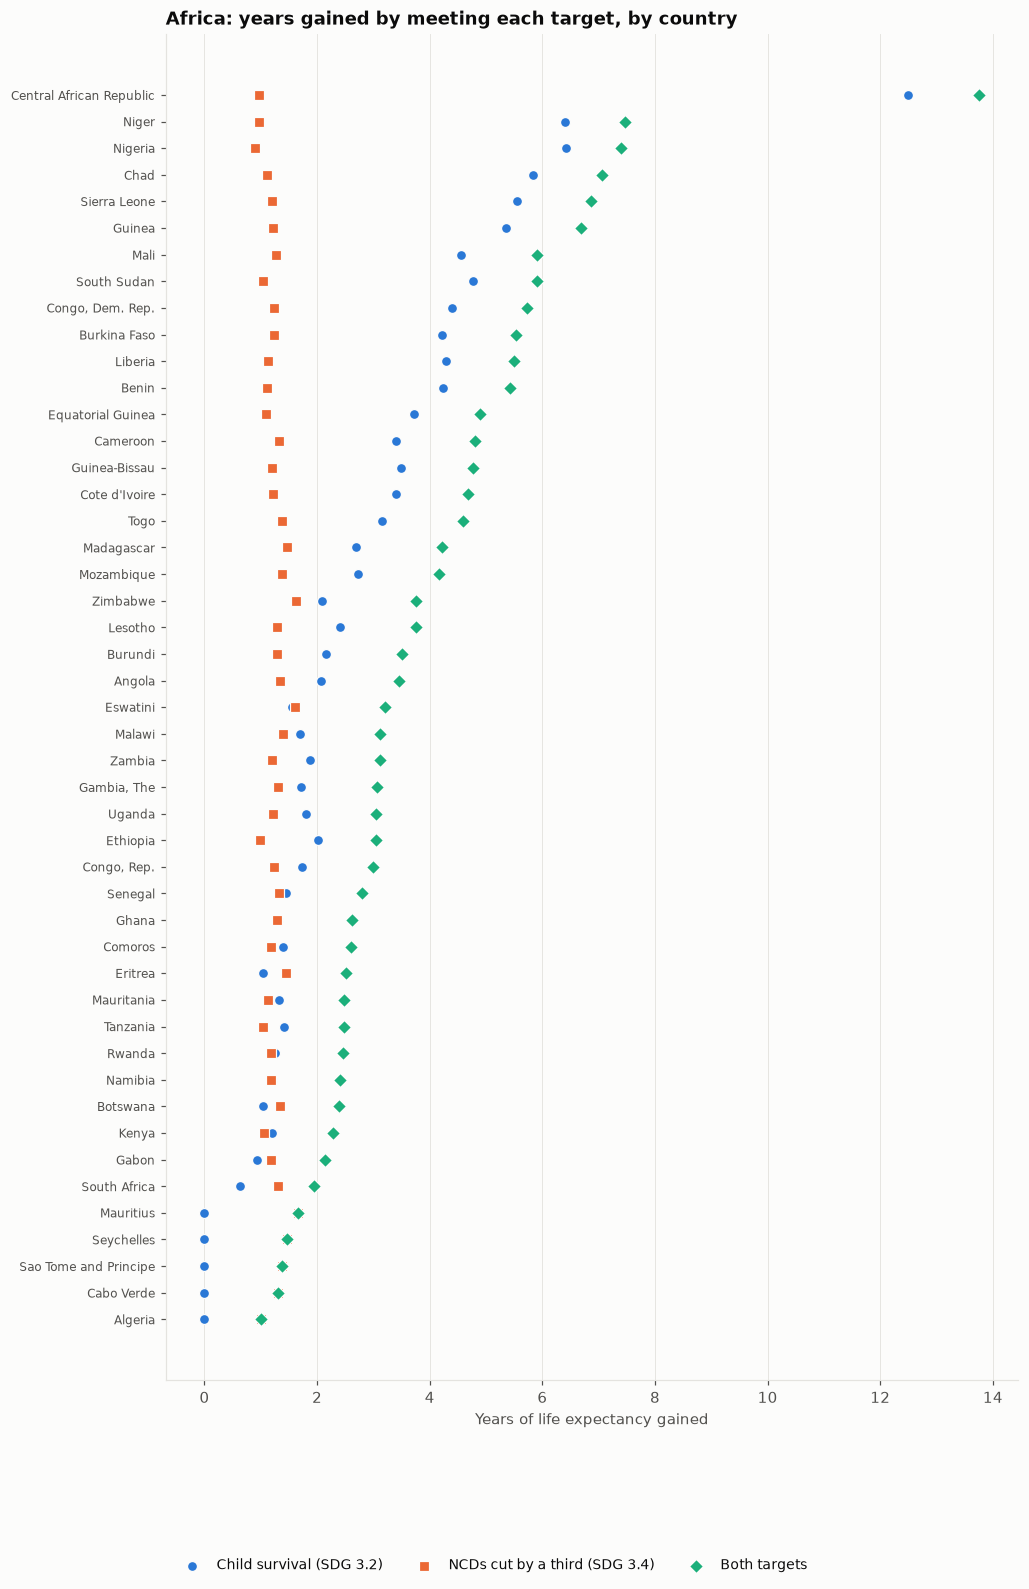

Countries with the most to gain from meeting both targets:


,country,who_region,e0,u5mr,child,ncd,combined,frontier
iso3,,,,,,,,
CAF,Central African Republic,Africa,42.23,253.79,12.50,0.96,13.76,25.80
NER,Niger,Africa,60.21,120.39,6.39,0.97,7.47,7.82
NGA,Nigeria,Africa,62.64,117.16,6.41,0.90,7.40,6.15
TCD,Chad,Africa,59.48,113.74,5.83,1.12,7.06,8.56
SLE,Sierra Leone,Africa,60.56,108.47,5.56,1.19,6.86,7.48
SOM,"Somalia, Fed. Rep.",Eastern Mediterranean,55.31,116.05,5.58,1.11,6.81,23.73
GIN,Guinea,Africa,61.08,104.88,5.35,1.22,6.68,6.96
MLI,Mali,Africa,62.48,92.34,4.55,1.26,5.91,5.57
SSD,South Sudan,Africa,59.74,98.12,4.77,1.05,5.90,8.29


In [3]:
reg = prev[prev["who_region"] == FOCUS_REGION].sort_values("combined")
fig, ax = plt.subplots(figsize=(10, 0.3 * len(reg) + 1.8))
y = np.arange(len(reg))
markers = {"child": "o", "ncd": "s", "combined": "D"}
for i, key in enumerate(["child", "ncd", "combined"]):
    ax.scatter(reg[key], y, marker=markers[key], s=42, color=PALETTE[i], label=SCENARIOS[key],
               edgecolor=SURFACE, linewidth=0.8, zorder=3)
ax.set_yticks(y, reg["country"], fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Years of life expectancy gained")
ax.set_title(f"{FOCUS_REGION}: years gained by meeting each target, by country")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.11 - 0.6 / len(reg)), ncol=3, fontsize=9)
save(fig, "21_prevention_countries")
plt.show()

top = prev.sort_values("combined", ascending=False).head(10)[["country", "who_region", "e0", "u5mr", "child", "ncd", "combined", "frontier"]]
print("Countries with the most to gain from meeting both targets:")
top.round(2)

**Questions to answer:** Where is child survival still the bigger prize, and where have NCDs overtaken it? Are there countries with high under-5 mortality *and* a large NCD burden? Those face the hardest trade-offs. Which countries already beat the child target, so that only the NCD scenario helps?

## 3. Women and men: who benefits from NCD prevention?

In [4]:
by_sex = {sex: prevention_scenarios(lt, panel, BASE_YEAR, sex) for sex in ["female", "male"]}
sex_table = pd.DataFrame({
    f"{sex} NCD gain": by_sex[sex].groupby("who_region").apply(lambda g: weighted_mean(g, "ncd"), include_groups=False)
    for sex in by_sex
})
sex_table[f"male minus female"] = sex_table["male NCD gain"] - sex_table["female NCD gain"]
print("Years gained from the NCD scenario by sex (same NCD share of the death rate applied to both sexes):")
sex_table.reindex(REGION_ORDER).round(2)

Years gained from the NCD scenario by sex (same NCD share of the death rate applied to both sexes):


,female NCD gain,male NCD gain,male minus female
who_region,,,
Africa,1.05,1.21,0.16
Americas,0.89,1.25,0.37
Eastern Mediterranean,1.30,1.52,0.21
Europe,0.88,1.48,0.60
South-East Asia,1.26,1.60,0.34
Western Pacific,0.99,1.50,0.51


This applies the same NCD *share* of the death rate to both sexes, so differences come only from men and women having different death rates at 30-69. Men usually gain more because their rates at those ages are higher (more smoking, more cardiovascular disease, later diagnosis). If you find the same, that supports targeting programmes at men, for example workplace blood pressure screening or tobacco cessation.

**Limitation:** in reality the NCD share also differs by sex. For a proper sex-specific analysis, replace the World Bank series with WHO's sex-disaggregated premature NCD mortality indicator.

## 4. Your focus country

In [5]:
row = prev.loc[FOCUS_COUNTRY]
print(f"{row['country']} in {BASE_YEAR}: life expectancy {row['e0']:.1f} years, under-5 mortality {row['u5mr']:.0f} per 1,000")
print(f"  Meeting the child-survival target would add {row['child']:.2f} years" +
      (" (already meets it)" if row['u5mr'] <= SDG_U5MR_TARGET * 1000 else ""))
if np.isfinite(row["ncd"]):
    print(f"  Cutting premature NCD mortality by a third would add {row['ncd']:.2f} years "
          f"(NCDs are about {row['ncd_share_30_70']:.0%} of the death rate at ages 30-69)")
print(f"  Both together: {row['combined']:.2f} years")
print(f"  Matching the best performers in {row['who_region']}: {row['frontier']:.2f} years")
rank = prev[prev["who_region"] == row["who_region"]]["combined"].rank(ascending=False)[FOCUS_COUNTRY]
print(f"  Rank in region for potential gain (both targets): {int(rank)} of {(prev['who_region'] == row['who_region']).sum()}")

Kenya in 2019: life expectancy 67.0 years, under-5 mortality 42 per 1,000
  Meeting the child-survival target would add 1.21 years
  Cutting premature NCD mortality by a third would add 1.06 years (NCDs are about 44% of the death rate at ages 30-69)
  Both together: 2.28 years
  Matching the best performers in Africa: 1.28 years
  Rank in region for potential gain (both targets): 40 of 47


## 5. Summary (generated from your data)

In [6]:
w = regional.loc["World"]
r = regional.drop("World")
print(f"- Using {BASE_YEAR} death rates, meeting the SDG child-survival target would raise world life expectancy by about "
      f"{w['child']:.2f} years, and cutting premature NCD deaths by a third by about {w['ncd']:.2f} years (population-weighted).")
print(f"- Both together: {w['combined']:.2f} years. Matching regional best performers: {w['frontier']:.2f} years.")
child_led = r.index[r["child"] > r["ncd"]].tolist()
ncd_led = r.index[r["ncd"] >= r["child"]].tolist()
if child_led:
    print(f"- Child survival is still the larger prize in: {', '.join(child_led)}.")
if ncd_led:
    print(f"- NCD prevention is now the larger prize in: {', '.join(ncd_led)}.")
print(f"- The biggest potential gains are in {r['combined'].idxmax()} ({r['combined'].max():.1f} years from both targets).")

- Using 2019 death rates, meeting the SDG child-survival target would raise world life expectancy by about 0.76 years, and cutting premature NCD deaths by a third by about 1.28 years (population-weighted).
- Both together: 2.06 years. Matching regional best performers: 3.79 years.
- Child survival is still the larger prize in: Africa.
- NCD prevention is now the larger prize in: Americas, Eastern Mediterranean, Europe, South-East Asia, Western Pacific.
- The biggest potential gains are in Africa (4.5 years from both targets).


## Bringing it together for your write-up

You now have the full chain of evidence that a health ministry or WHO reviewer looks for:

1. **What happened** (notebook 01): trends, gaps by region and sex, the COVID shock.
2. **Why it happened** (notebook 02): which ages drove the change, which causes those ages point to, and which conditions go with improvement.
3. **What to expect** (notebook 03): tested forecasts with honest intervals and scenarios.
4. **What could be done** (this notebook): how many years of life specific, agreed targets are worth, and where.

A strong final step is a **2-page policy brief** for one region or country with: three key findings with numbers, one chart each, the forecast range to 2030, the prevention potential, and limitations in plain language.